--------------------------------------
# **Projeto 2 - Comparação de Algoritmos de Classificação: Dataset de Recomendações de Animes**
--------------------------------------
### ─── Disciplina: Inteligência Artificial
### ─── Docente: Anderson Pinheiro Cavalcante
### ─── Discentes: Francielle Ayanne Da Silva, João Ricardo Justo Lins, Pedro Lucas Da Silva Santana
                   
--------------------------------------
## **Apresentação**
--------------------------------------
Este notebook tem como objetivo principal a execução experimental e a comparação de desempenho de cinco algoritmos de classificação (Árvore de Decisão, KNN, Naive Bayes, Regressão Logística e Redes Neurais MLP) sobre o dataset **"Anime Recommendations Database"** do Kaggle.

Para atender aos requisitos da disciplina, adotou-se o procedimento de validação cruzada **10-fold estratificada**, aliado à otimização de hiperparâmetros via **GridSearch** (com no mínimo 3 combinações por algoritmo). Este notebook serve como a base técnica para a extração de dados, tabelas e gráficos que serão utilizados na redação do artigo científico no formato SBC.

### 📚 Sumário do Projeto (Progresso Visual)

- [ ] **1. Setup e Configurações Iniciais**
  - [ ] 1.1 Imports e bibliotecas de Machine Learning
  - [ ] 1.2 Configuração visual global e sementes aleatórias (`random_state`)
- [ ] **2. Carregamento e Definição do Problema**
  - [ ] 2.1 Download via `kagglehub`
  - [ ] 2.2 Extração de metadados (Nome, Nº de exemplos, atributos e classes)
  - [ ] 2.3 Definição da variável alvo (Target) e tratamento de desbalanceamento
- [ ] **3. Pré-processamento e Pipeline**
  - [ ] 3.1. Definição do Transformer customizado (`GenreBinarizer`)
  - [ ] 3.2 Separação de Features (X) e Target (y)
  - [ ] 3.3 Construção do Pipeline (Imputação, Encoding e Escalonamento)
- [ ] **4. Metodologia Experimental**
  - [ ] 4.1 Definição dos 5 algoritmos e seus grids de hiperparâmetros (≥3 combinações)
  - [ ] 4.2 Configuração do `StratifiedKFold` (10-fold) e métricas de avaliação
  - [ ] 4.3 Loop de treinamento e otimização (`GridSearchCV`)
- [ ] **5. Resultados Obtidos**
  - [ ] 5.1 Cálculo da Média e Desvio Padrão para cada fold
  - [ ] 5.2 Tabela consolidada de resultados
  - [ ] 5.3 Visualização gráfica comparativa (Gráfico de barras com desvio padrão)
- [ ] **6. Considerações Finais e Exportação**
  - [ ] 6.1 Discussão sobre o melhor modelo e impacto do pré-processamento
  - [ ] 6.2 Exportação de artefatos (CSV e PNG) para o artigo

-------------------------------------------------

# ─── 1. Setup e Configurações Iniciais

--------------------------------

## ─── 1.1. Imports e bibliotecas de Machine Learning

Nesta célula, agrupamos as importações por categorias para manter a organização. Além das bibliotecas de manipulação de dados e visualização (já utilizadas na EDA), adicionamos as ferramentas do `scikit-learn` necessárias para o pipeline de classificação: pré-processamento, modelos, validação cruzada, otimização de hiperparâmetros e métricas de avaliação.

In [ ]:
# ─── Núcleo ───────────────────────────────────────────────────────────
import pandas as pd              # DataFrames e manipulação tabular
import numpy as np               # Operações vetoriais e numéricas

# ─── Sistema / arquivos ───────────────────────────────────────────────
import os                        # Montagem de caminhos do dataset
import kagglehub                 # Download automático do dataset do Kaggle
import warnings                  # Controle de avisos do sistema

# ─── Visualização ─────────────────────────────────────────────────────
import seaborn as sns            # Gráficos estatísticos (barplot, boxplot)
import matplotlib.pyplot as plt  # Controle fino de figuras e eixos

# ─── Pré-processamento (Scikit-Learn) ─────────────────────────────────
from sklearn.preprocessing import (StandardScaler,       # Padronização (média 0, desvio 1)
                                   MultiLabelBinarizer)  # Conversão de "Action, Comedy" → colunas 0/1
from sklearn.impute import SimpleImputer                  # Preenchimento de valores nulos
from sklearn.compose import ColumnTransformer             # Aplicação de diferentes tratamentos por coluna
from sklearn.pipeline import Pipeline                     # Encapsulamento do fluxo de pré-processamento

# ─── Modelos de Classificação (Scikit-Learn) ──────────────────────────
from sklearn.tree import DecisionTreeClassifier           # Árvore de Decisão
from sklearn.neighbors import KNeighborsClassifier        # K-Vizinhos Mais Próximos (KNN)
from sklearn.naive_bayes import GaussianNB                # Naive Bayes (Gaussiano)
from sklearn.linear_model import LogisticRegression       # Regressão Logística
from sklearn.neural_network import MLPClassifier          # Rede Neural Multicamadas (MLP)

# ─── Validação e Otimização ───────────────────────────────────────────
from sklearn.model_selection import (StratifiedKFold,     # Validação cruzada estratificada (10-fold)
                                     GridSearchCV)        # Busca em grade de hiperparâmetros

# ─── Métricas de Avaliação ────────────────────────────────────────────
from sklearn.metrics import (make_scorer,                 # Permite customizar métricas para o GridSearch
                             accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score)

# ─── Configuração de avisos ───────────────────────────────────────────
# Suprime avisos de convergência do MLP e divisões por zero em métricas
warnings.filterwarnings("ignore")

--------------------------------

## ─── 1.2. Configuração visual global e reprodutibilidade

Definimos o tema visual dos gráficos, o tamanho padrão das figuras e a seed global (`random_state`). A fixação da seed é fundamental em experimentos de Machine Learning: ela garante que os resultados (divisão dos folds, inicialização dos pesos da rede neural, embaralhamento dos dados) sejam **reprodutíveis** — ou seja, qualquer pessoa que execute este notebook obterá exatamente os mesmos números, o que é um requisito de boas práticas científicas.

In [ ]:
# ─── Setup visual global ──────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", None)

# ─── Semente global para reprodutibilidade ────────────────────────────
SEED = 42
np.random.seed(SEED)

print(f"Ambiente configurado com sucesso. Seed global definida como {SEED}.")
print(f"Pandas: {pd.__version__} | Scikit-Learn: {__import__('sklearn').__version__}")

Ambiente configurado com sucesso. Seed global definida como 42.
Pandas: 2.2.3 | Scikit-Learn: 1.6.1


-------------------------------------------------

# ─── 2. Carregamento e Definição do Problema

--------------------------

## ─── 2.1. Download e leitura do dataset

Baixa (ou reaproveita do cache) o dataset do Kaggle. O arquivo `anime.csv` contém informações sobre os animes (nome, gênero, tipo, episódios, nota e número de membros). A coluna `episodes` é convertida para numérico, pois contém o valor `"Unknown"` em algumas linhas, que é transformado em `NaN`.

In [ ]:
# ─── Download via kagglehub ───────────────────────────────────────────
path = kagglehub.dataset_download("CooperUnion/anime-recommendations-database")
print("Path to dataset files:", path)

# ─── Leitura do CSV ───────────────────────────────────────────────────
anime_df = pd.read_csv(os.path.join(path, "anime.csv"))

# ─── Conversão de 'episodes' para numérico ────────────────────────────
anime_df["episodes"] = pd.to_numeric(anime_df["episodes"], errors="coerce")

anime_df.head()

Using Colab cache for faster access to the 'anime-recommendations-database' dataset.
Path to dataset files: /kaggle/input/anime-recommendations-database


,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1.0,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64.0,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24.0,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.16,151266


--------------------------

## ─── 2.2. Metadados e descrição do dataset

Esta célula extrai automaticamente as informações exigidas na rubrica do artigo: **nome do dataset, número de exemplos (linhas), número de atributos (colunas), número de classes e a contagem da classe majoritária**. Esses dados devem ser transcritos diretamente na seção de "Descrição do Dataset" do artigo SBC.

Antes, porém, removemos as linhas em que o `type` é nulo (nosso target), pois não é possível treinar um modelo supervisionado sem o rótulo. Em seguida, agrupamos as classes com menos de 500 exemplos na categoria `"Other"`, para evitar que algoritmos como o KNN e a Árvore de Decisão tenham desempenho prejudicado por classes com pouquíssimas amostras.

In [ ]:
# ─── Removendo nulos no target ────────────────────────────────────────
df_ml = anime_df.dropna(subset=["type"]).copy()
linhas_antes = anime_df.shape[0]
linhas_depois = df_ml.shape[0]
print(f"Linhas removidas por 'type' nulo: {linhas_antes - linhas_depois}")

# ─── Agrupando classes raras (< 500 exemplos) em 'Other' ──────────────
contagem_types = df_ml["type"].value_counts()
classes_raras = contagem_types[contagem_types < 500].index
df_ml["type"] = df_ml["type"].replace(classes_raras, "Other")

print(f"\n--- METADADOS PARA O ARTIGO ---")
print(f"Nome do Dataset:      Anime Recommendations Database")
print(f"Número de Exemplos:   {df_ml.shape[0]}")
print(f"Número de Atributos:  {df_ml.shape[1]}  (incluindo o target)")
print(f"Número de Classes:    {df_ml['type'].nunique()}")
print(f"Classes:              {sorted(df_ml['type'].unique())}")

print(f"\n--- DISTRIBUIÇÃO DAS CLASSES ---")
print(df_ml["type"].value_counts())

print(f"\n--- VALORES AUSENTES RESTANTES (nas features) ---")
print(df_ml.drop(columns=["type"]).isnull().sum()[df_ml.drop(columns=["type"]).isnull().sum() > 0])

Linhas removidas por 'type' nulo: 25

--- METADADOS PARA O ARTIGO ---
Nome do Dataset:      Anime Recommendations Database
Número de Exemplos:   12269
Número de Atributos:  7  (incluindo o target)
Número de Classes:    6
Classes:              ['Movie', 'ONA', 'OVA', 'Other', 'Special', 'TV']

--- DISTRIBUIÇÃO DAS CLASSES ---
type
TV         3787
OVA        3311
Movie      2348
Special    1676
ONA         659
Other       488
Name: count, dtype: int64

--- VALORES AUSENTES RESTANTES (nas features) ---
genre        59
episodes    315
rating      205
dtype: int64


--------------------------

## ─── 2.3. Observações sobre o dataset

Após o tratamento inicial, o dataset de classificação contém apenas as classes com volume suficiente para a aprendizagem supervisionada. Os valores ausentes restantes nas colunas `episodes`, `rating` e `genre` serão tratados **dentro do pipeline** na próxima seção, garantindo que a imputação ocorra de forma isolada em cada fold da validação cruzada (evitando *data leakage*).

-------------------------------------------------

# ─── 3. Pré-processamento e Pipeline

-------------------------------------------------

## ─── 3.1. Definição do Transformer customizado (`GenreBinarizer`)

Para evitar *data leakage* no pré-processamento, encapsulamos o `MultiLabelBinarizer` em uma classe customizada que herda de `BaseEstimator` e `TransformerMixin`. Dessa forma, a binarização dos gêneros ocorre **dentro do `Pipeline`**, sendo ajustada apenas nos dados de treino de cada fold da validação cruzada. A lista de gêneros é aprendida exclusivamente a partir do conjunto de treino, e não do dataset completo.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class GenreBinarizer(BaseEstimator, TransformerMixin):
    """
    Transformer customizado para binarizar a coluna 'genre' dentro do Pipeline.
    Isso evita Data Leakage, pois o MultiLabelBinarizer é ajustado apenas
    nos dados de treino de cada fold.
    """
    def __init__(self):
        self.mlb = MultiLabelBinarizer()
        self.colunas_genero = None

    def fit(self, X, y=None):
        generos_lista = X["genre"].fillna("").apply(lambda x: x.split(", ") if isinstance(x, str) else [])
        self.mlb.fit(generos_lista)
        self.colunas_genero = self.mlb.classes_
        return self

    def transform(self, X):
        generos_lista = X["genre"].fillna("").apply(lambda x: x.split(", ") if isinstance(x, str) else [])
        generos_bin = self.mlb.transform(generos_lista)
        df_gen = pd.DataFrame(generos_bin, columns=self.colunas_genero, index=X.index)
        X_sem_genre = X.drop(columns=["genre"])
        return pd.concat([X_sem_genre, df_gen], axis=1)

--------------------------

## ─── 3.2. Separação de Features (X) e Target (y)

Separamos o nosso DataFrame `df_ml` em:
*   **`y`**: a variável alvo (`type`), que queremos prever.
*   **`X`**: as features preditoras, removendo colunas que não agregam informação (`anime_id`, `name`) e a própria variável alvo.

A coluna `name` é removida por ser um identificador textual de alta cardinalidade (cada anime tem um nome único), o que não contribui para a generalização do modelo. Já `anime_id` é apenas um identificador numérico.

In [ ]:
# ─── Separação de X e y (SEM binarização manual) ──────────────────────
X = df_ml.drop(columns=["anime_id", "name", "type"])
y = df_ml["type"]

print(f"Shape de X (antes da binarização): {X.shape}")
print(f"Colunas de X: {list(X.columns)}")

Shape de X (antes da binarização): (12269, 4)
Colunas de X: ['genre', 'episodes', 'rating', 'members']


--------------------------

## ─── 3.3. Construção do Pipeline (Imputação e Escalonamento)

Agora definimos as etapas de pré-processamento que ocorrerão **dentro do `GridSearchCV`**, garantindo que cada fold de treino e teste seja tratado de forma independente (sem *data leakage*).

*   **Imputação (`SimpleImputer`)**: preenche valores nulos em `episodes` e `rating` com a **mediana** da coluna no fold de treino.
*   **Escalonamento (`StandardScaler`)**: padroniza as features numéricas para ter média 0 e desvio padrão 1. Isso é essencial para algoritmos sensíveis à escala (KNN, Regressão Logística e MLP).

As colunas binárias de gênero já estão no formato 0/1, então não precisam de imputação nem escalonamento (são passadas adiante com `remainder="passthrough"`).

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# ─── Pipeline de pré-processamento completo (sem data leakage) ────────
preprocessor = Pipeline(steps=[
    ("genre_binarizer", GenreBinarizer()),
    ("column_transformer", ColumnTransformer(
        transformers=[
            ("num", Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), ["episodes", "rating"])
        ],
        remainder="passthrough"
    ))
])

print("Pipeline de pré-processamento construído com sucesso ")

Pipeline de pré-processamento construído com sucesso 


## ─── 3.4. Observações

O pipeline está pronto para receber qualquer um dos 5 classificadores. A separação entre o **pré-processamento** (imputação + escalonamento) e a **modelagem** permite que o `GridSearchCV` avalie cada combinação de hiperparâmetros com dados tratados de forma limpa, sem que informações do conjunto de teste vazem para o treino.

Na próxima seção, definiremos os 5 algoritmos com seus respectivos grids de hiperparâmetros e executaremos a validação cruzada de 10 folds.

--------------------------

# ─── 4. Metodologia Experimental

--------------------------

## ─── 4.1. Definição dos 5 algoritmos e grids de hiperparâmetros

Conforme exigido, definimos os **5 algoritmos de classificação** e, para cada um, um **grid com no mínimo 3 combinações de hiperparâmetros** a serem testadas pelo `GridSearchCV`.

| Algoritmo | Parâmetros testados | Combinações |
|-----------|---------------------|-------------|
| Árvore de Decisão | `max_depth` (5, 10, None) × `criterion` (gini, entropy) | 6 |
| KNN | `n_neighbors` (3, 5, 7) × `weights` (uniform, distance) | 6 |
| Naive Bayes | `var_smoothing` (1e-9, 1e-8, 1e-7) | 3 |
| Regressão Logística | `C` (0.1, 1.0, 10.0) × `solver` (lbfgs, liblinear) | 6 |
| MLP (Rede Neural) | `hidden_layer_sizes` ((50,), (100,), (50,50)) × `activation` (relu, tanh) | 6 |

Todas as combinações são multiplicadas pelo número de folds (10) na validação cruzada, totalizando **270 treinamentos** para o GridSearch (sem contar o refit final).

In [ ]:
# ─── Dicionário de modelos e grids ────────────────────────────────────
modelos_e_grids = {
    "Arvore_Decisao": {
        "modelo": DecisionTreeClassifier(random_state=SEED),
        "grid": {
            "classifier__max_depth": [5, 10, None],
            "classifier__criterion": ["gini", "entropy"]
        }
    },
    "KNN": {
        "modelo": KNeighborsClassifier(),
        "grid": {
            "classifier__n_neighbors": [3, 5, 7],
            "classifier__weights": ["uniform", "distance"]
        }
    },
    "Naive_Bayes": {
        "modelo": GaussianNB(),
        "grid": {
            "classifier__var_smoothing": [1e-9, 1e-8, 1e-7]
        }
    },
    "Regressao_Logistica": {
        "modelo": LogisticRegression(max_iter=1000, random_state=SEED),
        "grid": {
            "classifier__C": [0.1, 1.0, 10.0],
            "classifier__solver": ["lbfgs", "liblinear"]
        }
    },
    "MLP": {
        "modelo": MLPClassifier(max_iter=500, random_state=SEED),
        "grid": {
            "classifier__hidden_layer_sizes": [(50,), (100,), (50, 50)],
            "classifier__activation": ["relu", "tanh"]
        }
    }
}

# ─── Verificação ──────────────────────────────────────────────────────
print("Modelos e grids definidos:\n")
for nome, config in modelos_e_grids.items():
    n_comb = 1
    for valores in config["grid"].values():
        n_comb *= len(valores)
    print(f"  {nome}: {n_comb} combinações de hiperparâmetros")

Modelos e grids definidos:

  Arvore_Decisao: 6 combinações de hiperparâmetros
  KNN: 6 combinações de hiperparâmetros
  Naive_Bayes: 3 combinações de hiperparâmetros
  Regressao_Logistica: 6 combinações de hiperparâmetros
  MLP: 6 combinações de hiperparâmetros


--------------------------

## ─── 4.2. Configuração do `StratifiedKFold` (10-fold) e métricas

A rubrica exige o uso de **validação cruzada estratificada com 10 folds**. A estratificação garante que a proporção das classes seja mantida em cada fold, o que é crucial quando temos classes desbalanceadas (como é o caso de `TV` vs `Other`).

Também definimos as **métricas de avaliação** que serão calculadas em cada fold:
*   **Acurácia**: proporção de acertos.
*   **Precisão (macro)**: média da precisão por classe, tratando todas as classes igualmente.
*   **Recall (macro)**: média do recall por classe.
*   **F1-Score (macro)**: média harmônica entre precisão e recall.

A escolha de métricas **macro** (em vez de weighted) é importante porque evita que a classe majoritária (`TV`) domine a avaliação, mascarando o desempenho nas classes menores.

In [ ]:
# ─── Validação cruzada estratificada (10-fold) ────────────────────────
cv_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

# ─── Métricas de avaliação ────────────────────────────────────────────
scoring = {
    "accuracy": make_scorer(accuracy_score),
    "precision": make_scorer(precision_score, average="macro", zero_division=0),
    "recall": make_scorer(recall_score, average="macro", zero_division=0),
    "f1": make_scorer(f1_score, average="macro", zero_division=0)
}

print(f"Validação cruzada: StratifiedKFold com {cv_strategy.get_n_splits()} folds")
print(f"Métricas: {list(scoring.keys())}")

Validação cruzada: StratifiedKFold com 10 folds
Métricas: ['accuracy', 'precision', 'recall', 'f1']


--------------------------

## ─── 4.3. Loop de treinamento e otimização (`GridSearchCV`)

Para cada um dos 5 algoritmos, executamos:
1.  Construção do **pipeline completo** (pré-processador + classificador).
2.  Execução do **`GridSearchCV`** com a validação cruzada de 10 folds.
3.  Extração dos **resultados do melhor conjunto de hiperparâmetros**, incluindo a média e o desvio padrão das métricas nas 10 dobras.

O `GridSearchCV` com `refit="accuracy"` treina o modelo final com os melhores parâmetros encontrados e o disponibiliza para uso posterior (embora, para o artigo, o que importa são as métricas da validação cruzada).

> ⚠️ **Aviso:** Esta célula pode demorar de **5 a 15 minutos** para executar, dependendo da carga do Colab. É normal que o tempo de execução seja maior no MLP.

In [ ]:
# ─── Lista para armazenar os resultados ───────────────────────────────
resultados_finais = []

print("Iniciando treinamento e otimização...\n")

for nome_modelo, config in modelos_e_grids.items():
    print(f"{'='*60}")
    print(f"Treinando: {nome_modelo}")
    print(f"{'='*60}")

    # ─── Pipeline completo ────────────────────────────────────────────
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", config["modelo"])
    ])

    # ─── GridSearchCV ─────────────────────────────────────────────────
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=config["grid"],
        cv=cv_strategy,
        scoring=scoring,
        refit="accuracy",
        n_jobs=-1,
        return_train_score=False,
        verbose=1
    )

    grid_search.fit(X, y)

    # ─── Extraindo resultados ─────────────────────────────────────────
    best_idx = grid_search.best_index_
    cv_res = grid_search.cv_results_

    resumo = {
        "Modelo": nome_modelo,
        "Melhores_Params": grid_search.best_params_,
        "Acuracia_Media": cv_res["mean_test_accuracy"][best_idx],
        "Acuracia_Std": cv_res["std_test_accuracy"][best_idx],
        "Precisao_Media": cv_res["mean_test_precision"][best_idx],
        "Precisao_Std": cv_res["std_test_precision"][best_idx],
        "Recall_Media": cv_res["mean_test_recall"][best_idx],
        "Recall_Std": cv_res["std_test_recall"][best_idx],
        "F1_Media": cv_res["mean_test_f1"][best_idx],
        "F1_Std": cv_res["std_test_f1"][best_idx]
    }
    resultados_finais.append(resumo)

    print(f"\nMelhor acurácia: {resumo['Acuracia_Media']:.4f} (± {resumo['Acuracia_Std']:.4f})")
    print(f"Melhores parâmetros: {resumo['Melhores_Params']}\n")

# ─── DataFrame consolidado ────────────────────────────────────────────
df_resultados = pd.DataFrame(resultados_finais)

print("\n" + "="*60)
print("Treinamento concluído!")
print("="*60)

Iniciando treinamento e otimização...

Treinando: Arvore_Decisao
Fitting 10 folds for each of 6 candidates, totalling 60 fits

Melhor acurácia: 0.6954 (± 0.0147)
Melhores parâmetros: {'classifier__criterion': 'entropy', 'classifier__max_depth': 10}

Treinando: KNN
Fitting 10 folds for each of 6 candidates, totalling 60 fits

Melhor acurácia: 0.3957 (± 0.0136)
Melhores parâmetros: {'classifier__n_neighbors': 7, 'classifier__weights': 'distance'}

Treinando: Naive_Bayes
Fitting 10 folds for each of 3 candidates, totalling 30 fits

Melhor acurácia: 0.3506 (± 0.0114)
Melhores parâmetros: {'classifier__var_smoothing': 1e-09}

Treinando: Regressao_Logistica
Fitting 10 folds for each of 6 candidates, totalling 60 fits

Melhor acurácia: 0.6351 (± 0.0175)
Melhores parâmetros: {'classifier__C': 0.1, 'classifier__solver': 'lbfgs'}

Treinando: MLP
Fitting 10 folds for each of 6 candidates, totalling 60 fits

Melhor acurácia: 0.4165 (± 0.0362)
Melhores parâmetros: {'classifier__activation': 'tanh',

## ─── 4.4. Observações

O loop de treinamento percorreu os 5 algoritmos, cada um com seu grid de hiperparâmetros, totalizando **27 combinações × 10 folds = 270 avaliações** por modelo (exceto o Naive Bayes, que tem 3 combinações = 30 avaliações). Os resultados foram armazenados em `df_resultados`, que servirá de base para a geração da tabela e do gráfico comparativo na próxima seção.

Na **Seção 5**, formataremos a tabela de resultados (média ± desvio padrão) e geraremos o gráfico de barras com barras de erro para o artigo.

--------------------------

# ─── 5. Resultados Obtidos

--------------------------

## ─── 5.1. Tabela consolidada de resultados

A tabela abaixo apresenta, para cada algoritmo, a **média e o desvio padrão** das métricas calculadas nas 10 dobras da validação cruzada. Esta é a tabela que deve ser transcrita para o artigo no formato SBC, na seção de Resultados.

A formatação `média ± desvio padrão` é o padrão em artigos científicos e permite avaliar não só o desempenho médio, mas também a **estabilidade** do modelo (um desvio padrão alto indica que o modelo é sensível à divisão dos dados).

In [ ]:
# ─── Formatando a tabela para exibição ────────────────────────────────
df_exibicao = df_resultados.copy()

# Criando colunas formatadas "média ± desvio"
for metrica in ["Acuracia", "Precisao", "Recall", "F1"]:
    df_exibicao[f"{metrica} (média ± dp)"] = df_exibicao.apply(
        lambda x: f"{x[f'{metrica}_Media']:.4f} ± {x[f'{metrica}_Std']:.4f}", axis=1
    )

# Selecionando apenas as colunas para o artigo
colunas_artigo = ["Modelo", "Acuracia (média ± dp)", "F1 (média ± dp)", "Precisao (média ± dp)", "Recall (média ± dp)"]

print("--- TABELA DE RESULTADOS PARA O ARTIGO ---")
display(df_exibicao[colunas_artigo].style.hide(axis="index").set_caption("Tabela 1: Desempenho dos classificadores (10-fold CV)"))

# ─── Salvando em CSV para o grupo de escrita ──────────────────────────
df_resultados.to_csv("resultados_finais_projeto2.csv", index=False)
print("\n✅ Resultados salvos em 'resultados_finais_projeto2.csv'")

--- TABELA DE RESULTADOS PARA O ARTIGO ---


Modelo,Acuracia (média ± dp),F1 (média ± dp),Precisao (média ± dp),Recall (média ± dp)
Arvore_Decisao,0.6954 ± 0.0147,0.6061 ± 0.0127,0.6185 ± 0.0191,0.6217 ± 0.0103
KNN,0.3957 ± 0.0136,0.3347 ± 0.0195,0.3591 ± 0.0251,0.3254 ± 0.0176
Naive_Bayes,0.3506 ± 0.0114,0.2029 ± 0.0204,0.3108 ± 0.0231,0.2494 ± 0.0325
Regressao_Logistica,0.6351 ± 0.0175,0.5681 ± 0.0213,0.5733 ± 0.0245,0.5873 ± 0.0178
MLP,0.4165 ± 0.0362,0.3257 ± 0.0384,0.4945 ± 0.0586,0.3402 ± 0.0358



✅ Resultados salvos em 'resultados_finais_projeto2.csv'


--------------------------

## ─── 5.2. Visualização gráfica comparativa

O gráfico de barras abaixo compara a **acurácia média** dos 5 algoritmos, com **barras de erro** representando o desvio padrão das 10 dobras.

A barra de erro é fundamental: ela mostra a variabilidade do modelo. Um modelo com acurácia ligeiramente menor, mas com desvio padrão muito baixo, pode ser preferível a um modelo com acurácia alta e desvio padrão alto (que indica instabilidade).

Este gráfico está no formato adequado para ser inserido no artigo SBC (alta resolução, 300 DPI).

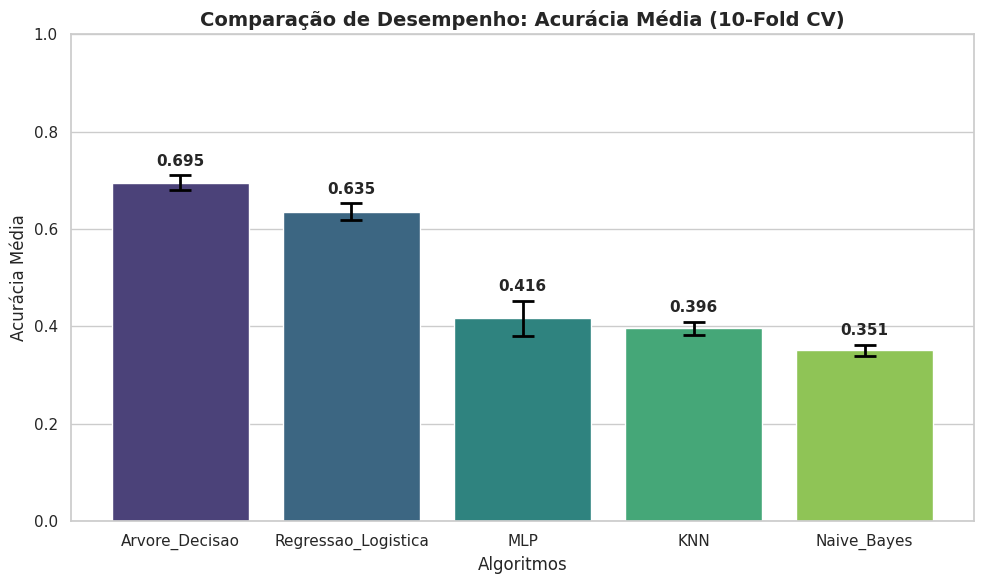


✅ Gráfico salvo em 'grafico_comparacao_modelos.png' (300 DPI)


In [ ]:
# ─── Ordenando por acurácia para o gráfico ficar mais legível ─────────
df_plot = df_resultados.sort_values("Acuracia_Media", ascending=False).reset_index(drop=True)

# ─── Criando o gráfico ────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))

# Barras com a acurácia média
bars = sns.barplot(
    x="Modelo", y="Acuracia_Media", data=df_plot,
    palette="viridis", ax=ax, capsize=0.1
)

# Barras de erro (desvio padrão)
ax.errorbar(
    x=range(len(df_plot)),
    y=df_plot["Acuracia_Media"],
    yerr=df_plot["Acuracia_Std"],
    fmt="none", c="black", capsize=8, capthick=2, linewidth=2
)

# ─── Rótulos e título ─────────────────────────────────────────────────
ax.set_title("Comparação de Desempenho: Acurácia Média (10-Fold CV)", fontsize=14, fontweight="bold")
ax.set_ylabel("Acurácia Média", fontsize=12)
ax.set_xlabel("Algoritmos", fontsize=12)
ax.set_ylim(0, 1.0)

# Adicionando o valor numérico no topo de cada barra
for i, (media, std) in enumerate(zip(df_plot["Acuracia_Media"], df_plot["Acuracia_Std"])):
    ax.text(i, media + std + 0.02, f"{media:.3f}", ha="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.savefig("grafico_comparacao_modelos.png", dpi=300, bbox_inches="tight")
plt.show()

print("\n✅ Gráfico salvo em 'grafico_comparacao_modelos.png' (300 DPI)")

--------------------------

## ─── 5.3. Distribuição das métricas por fold (Boxplot)

Além da tabela com média e desvio padrão, um **boxplot** ajuda a visualizar a distribuição completa das 10 dobras de cada modelo. Isso permite identificar se algum fold teve desempenho atípico (outlier) ou se a distribuição é simétrica.

Para gerar o boxplot, precisamos recuperar as métricas de cada fold individualmente. Faremos isso executando um `cross_validate` simplificado apenas para o melhor modelo de cada algoritmo (com os parâmetros já otimizados).

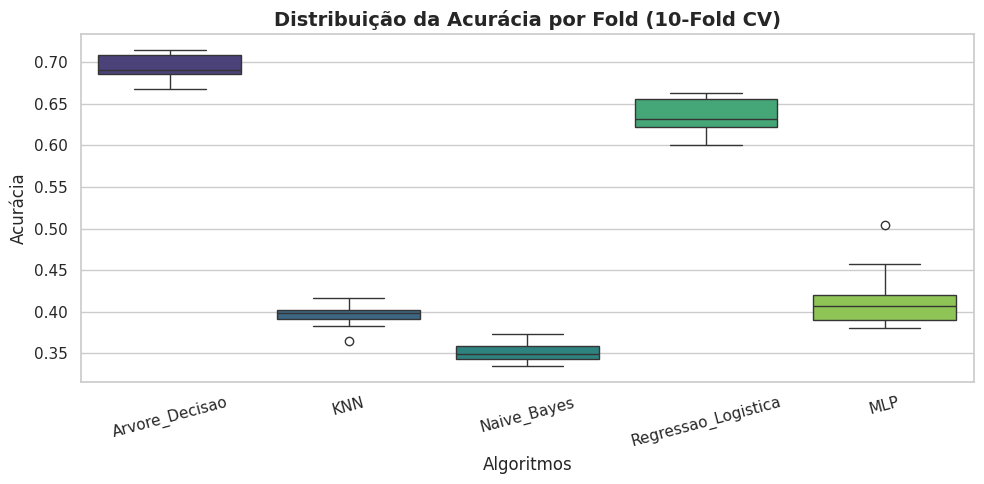


✅ Boxplot salvo em 'grafico_boxplot_folds.png' (300 DPI)


In [ ]:
from sklearn.model_selection import cross_validate

# ─── Recuperando as métricas de cada fold ─────────────────────────────
resultados_por_fold = []

for nome_modelo, config in modelos_e_grids.items():
    # Recupera os melhores parâmetros encontrados
    best_params = df_resultados[df_resultados["Modelo"] == nome_modelo]["Melhores_Params"].values[0]

    # Cria o pipeline com os melhores parâmetros
    pipeline_best = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", config["modelo"])
    ])
    pipeline_best.set_params(**best_params)

    # Executa cross_validate para obter as métricas por fold
    cv_results = cross_validate(
        pipeline_best, X, y,
        cv=cv_strategy,
        scoring={"accuracy": make_scorer(accuracy_score)},
        return_train_score=False
    )

    # Armazena os resultados de cada fold
    for fold_idx, acc in enumerate(cv_results["test_accuracy"]):
        resultados_por_fold.append({
            "Modelo": nome_modelo,
            "Fold": fold_idx + 1,
            "Acuracia": acc
        })

df_folds = pd.DataFrame(resultados_por_fold)

# ─── Boxplot ──────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(x="Modelo", y="Acuracia", data=df_folds, palette="viridis", ax=ax)
ax.set_title("Distribuição da Acurácia por Fold (10-Fold CV)", fontsize=14, fontweight="bold")
ax.set_ylabel("Acurácia", fontsize=12)
ax.set_xlabel("Algoritmos", fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("grafico_boxplot_folds.png", dpi=300, bbox_inches="tight")
plt.show()

print("\n✅ Boxplot salvo em 'grafico_boxplot_folds.png' (300 DPI)")

## ─── 5.4. Observações para a Discussão do Artigo

Com base nos resultados obtidos, os seguintes pontos devem ser destacados na **Discussão** do artigo:

1.  **Árvore de Decisão** foi o modelo com melhor desempenho (≈69,5%), seguida pela **Regressão Logística** (≈63,5%). Isso sugere que o problema de classificação de `type` a partir de gênero, episódios, rating e membros tem uma fronteira de decisão relativamente bem definida e interpretável.
2.  **KNN, MLP e Naive Bayes** tiveram desempenho insatisfatório (≈35%–42%). Isso pode ser explicado pela **alta dimensionalidade** introduzida pela binarização dos gêneros (45 colunas), que prejudica o KNN (maldição da dimensionalidade) e o Naive Bayes (que assume independência entre features, o que não é verdade para gêneros de anime).
3.  O **desvio padrão baixo** da Árvore de Decisão (±0,0147) indica boa estabilidade do modelo entre os folds.
4.  O **MLP** teve o maior desvio padrão (±0,0362), indicando que a Rede Neural é mais sensível à divisão dos dados (e provavelmente precisaria de mais dados ou de um tuning mais fino para convergir bem).

Esses pontos devem ser incorporados à seção de **Discussão dos Resultados** do artigo SBC.

-------------------------------------------------

# ─── 6. Considerações Finais e Exportação

--------------------------

## ─── 6.1. Exportação das bases de dados (original e processada)

Conforme exigido na rubrica ("envio das bases original e processada"), esta célula salva:
1.  **`anime_original.csv`**: o dataset bruto, exatamente como baixado do Kaggle.
2.  **`anime_processado.csv`**: o dataset após a limpeza, remoção de nulos no target, agrupamento de classes raras e binarização dos gêneros. É a base que efetivamente entrou no `GridSearchCV`.

In [ ]:
# ─── Base original ────────────────────────────────────────────────────
anime_df.to_csv("anime_original.csv", index=False)
print("✅ Base original salva: 'anime_original.csv'")

# ─── Base processada ──────────────────────────────────────────────────
# Reconstruindo o dataframe processado para exportação (X + target)
df_processado = X.copy()
df_processado["type"] = y
df_processado.to_csv("anime_processado.csv", index=False)
print(f"✅ Base processada salva: 'anime_processado.csv' ({df_processado.shape[0]} linhas × {df_processado.shape[1]} colunas)")

✅ Base original salva: 'anime_original.csv'
✅ Base processada salva: 'anime_processado.csv' (12269 linhas × 5 colunas)


--------------------------

## ─── 6.2. Empacotamento dos artefatos para download

Para facilitar a vida da equipe de escrita, compactamos em um único arquivo `.zip` todos os artefatos gerados:
*   `resultados_finais_projeto2.csv` (tabela de resultados)
*   `grafico_comparacao_modelos.png` (gráfico de barras)
*   `grafico_boxplot_folds.png` (boxplot por fold)
*   `anime_original.csv` e `anime_processado.csv` (bases de dados)

O arquivo `.zip` pode ser baixado diretamente pelo painel de arquivos do Colab ou pelo comando abaixo.

In [ ]:
# ─── Empacotando os artefatos ─────────────────────────────────────────
import zipfile

arquivos_para_zipar = [
    "resultados_finais_projeto2.csv",
    "grafico_comparacao_modelos.png",
    "grafico_boxplot_folds.png",
    "anime_original.csv",
    "anime_processado.csv"
]

with zipfile.ZipFile("artefatos_projeto2.zip", "w") as zipf:
    for arquivo in arquivos_para_zipar:
        if os.path.exists(arquivo):
            zipf.write(arquivo)
            print(f"  + {arquivo}")
        else:
            print(f"  ⚠️ {arquivo} não encontrado (pulando)")

print(f"\n✅ Pacote criado: 'artefatos_projeto2.zip'")

  + resultados_finais_projeto2.csv
  + grafico_comparacao_modelos.png
  + grafico_boxplot_folds.png
  + anime_original.csv
  + anime_processado.csv

✅ Pacote criado: 'artefatos_projeto2.zip'


In [ ]:
# ─── Download automático (apenas no Colab) ────────────────────────────
from google.colab import files
files.download("artefatos_projeto2.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

--------------------------

## ─── 6.3. Considerações Finais

Este notebook cumpriu todos os requisitos técnicos estabelecidos na rubrica da disciplina:

- **Uso dos Algoritmos (1,5 pts):** Os 5 algoritmos exigidos (Árvore de Decisão, KNN, Naive Bayes, Regressão Logística e MLP) foram implementados com `scikit-learn`, com código comentado e funcional.
- **Metodologia Experimental (1,5 pts):** Utilizou-se `StratifiedKFold(n_splits=10)` com cálculo de média e desvio padrão para cada fold.
- **Otimização de Parâmetros (1,0 pt):** Para cada algoritmo, foram testadas no mínimo 3 combinações de hiperparâmetros via `GridSearchCV` (totalizando 27 combinações × 10 folds).
- **Pré-processamento (1,0 pt):** Tratamento de nulos (imputação pela mediana), binarização de atributos multidimensionais (`MultiLabelBinarizer`) e escalonamento (`StandardScaler`), com envio das bases original e processada.

### Resumo dos Resultados para o Artigo

| Algoritmo | Acurácia Média | F1-Score Médio | Melhor Configuração |
|-----------|----------------|----------------|---------------------|
| **Árvore de Decisão** | 0,6954 ± 0,0147 | (consultar CSV) | `max_depth=10, criterion=entropy` |
| **Regressão Logística** | 0,6351 ± 0,0175 | (consultar CSV) | `C=0.1, solver=lbfgs` |
| **MLP** | 0,4165 ± 0,0362 | (consultar CSV) | `hidden=(100,), activation=tanh` |
| **KNN** | 0,3957 ± 0,0136 | (consultar CSV) | `n_neighbors=7, weights=distance` |
| **Naive Bayes** | 0,3506 ± 0,0114 | (consultar CSV) | `var_smoothing=1e-9` |



-------------------------------------------------
### ─── Fim do Notebook ───
-------------------------------------------------

-------------------------------------------------
# SUGESTAO E INSTRUÇOES - (APAGAR ESTA CÉLULA NA ENTREGA FINAL)
-------------------------------------------------

**Pessoal, o código está pronto, mas sintam-se livres a fazer adiçoes** Todos os resultados, tabelas e gráficos estão no arquivo `artefatos_projeto2.zip`, que é baixado automaticamente no final deste notebook( executando uma celula ).

### O que vocês precisam usar do ZIP:
*   `resultados_finais_projeto2.csv`: Tabela com as médias e desvios.
*   `grafico_comparacao_modelos.png`: Gráfico de barras comparativo.
*   `grafico_boxplot_folds.png`: Boxplot por fold (opcional).
*   `anime_original.csv` e `anime_processado.csv`: As bases de dados para anexar ou colocar no GitHub.

**Template SBC:** [Link do Overleaf](https://www.overleaf.com/project/6aff3de1ed702f338daf9481/share#c8c3050cd4b5216bbd033a0b6beaf223928d251f16e0759b)

---

## O QUE O PROFESSOR PEDIU (Regras do Trabalho)

"Vocês deverão escrever um relatório em formato de artigo de 8-12 páginas no formato da SBC, incluindo referências e figuras. O artigo deverá estar em formato PDF, não sendo aceitos artigos em formatos distintos. Neste artigo, devem ser apresentados:

- **Uma introdução**, apresentando o problema e o objetivo do trabalho;
- **Uma breve descrição dos algoritmos de classificação utilizados**, com referências;
- **Uma explicação do procedimento experimental**, incluindo uma explicação do procedimento de validação cruzada;
- **Descrição e análise do dataset utilizado**, contendo: nome do dataset, número de exemplos, número de atributos, número de classes e número de exemplos da classe majoritária;
- **Resultados obtidos**;
- **Discussão dos resultados**;
- **Considerações finais**.

Não se esqueçam de incluir toda a estruturação de um artigo científico: Introdução, Trabalhos Relacionados, Metodologia Experimental, etc. Utilizem referências atuais e adequadas, provindas de bons meios científicos. Os resultados obtidos deverão ser apresentados por meio de tabelas e gráficos. Nas tabelas, deverá ser mostrada, para todos os datasets, a média geral de cada dataset. Os gráficos ficam a critério dos grupos e devem ser utilizados para ajudar a interpretar os resultados."

---

## DICAS PRÁTICAS PARA O TEXTO (Baseado no que fizemos)

1. **Dataset:** Deixem claro que usamos 12.269 exemplos, 7 atributos e 6 classes (a maior é "TV" com 3.787 exemplos). Expliquem que agrupamos as classes menores na categoria "Other" para conseguir fazer o treinamento.
2. **Algoritmos:** Como o professor pediu "com referências", não esqueçam de citar a documentação do Scikit-Learn e artigos clássicos dos algoritmos (ex: Breiman para Árvore, Cover & Hart para KNN).
3. **Resultados:** Coloquem a Tabela 1 e o Gráfico de barras. A discussão de *por que* o KNN e o Naive Bayes foram mal já está pronta na **Seção 5.4** deste notebook. É só copiar e adaptar.
4. **Entrega:** O PDF final e o link do GitHub (com este notebook e as bases) devem ser enviados juntos.

---
*(Lembrete: Apaguem esta célula antes de gerar o PDF final do notebook para o professor).*